**LIBRERÍAS**

In [1]:
#!/usr/bin/python

import pandas as pd 
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from keras.models import Sequential
from keras.layers import GRU, Dense
from keras.layers import LSTM, Concatenate
from keras  import callbacks
from keras import optimizers

**OBTENCIÓN DE DATOS**

         Passengers
Month              
1949-01       112.0
1949-02       118.0
1949-03       132.0
1949-04       129.0
1949-05       121.0


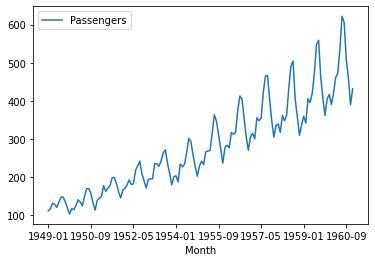

In [2]:
url = 'https://raw.githubusercontent.com/ivanarielcaceres/timeseries-lstm-keras/master/data/international-airline-passengers.csv'
df = pd.read_csv(url, index_col='Month')
print(df.head())
df.plot()

In [3]:
columns_to_keep = ['Passengers']
df = df[columns_to_keep]
df['Passengers'] = df['Passengers'].apply(lambda x: x*1000)
df.index.names = ['Month']
df.sort_index(inplace=True)
print('Total rows: {}'.format(len(df)))
df.head()

Total rows: 146


,Passengers
Month,
1949-01,112000.0
1949-02,118000.0
1949-03,132000.0
1949-04,129000.0
1949-05,121000.0


In [4]:
df.describe()

,Passengers
count,144.000000
mean,280298.611111
std,119966.316943
min,104000.000000
25%,180000.000000
50%,265500.000000
75%,360500.000000
max,622000.000000


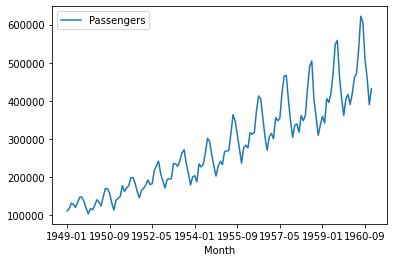

In [5]:
df.plot()

**PREPROCESAMIENTO DE DATOS**

*   **ELIMINAR VALORES FALTANTES**

In [6]:
df.isnull().sum()

Passengers    2
dtype: int64

In [7]:
null_columns=df.columns[df.isnull().any()]
df[null_columns].isnull().sum()

Passengers    2
dtype: int64

In [8]:
print(df[df.isnull().any(axis=1)][null_columns].head())

                                                    Passengers
Month                                                         
International airline passengers: monthly total...         NaN
NaN                                                        NaN


In [9]:
df.dropna(inplace=True)

In [10]:
df.isnull().sum()

Passengers    0
dtype: int64

array([[<matplotlib.axes._subplots.AxesSubplot object at 0x7fc7db7d1dd0>]],
      dtype=object)

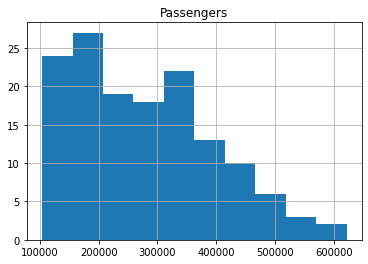

In [11]:
df.hist(bins=10)

In [12]:
len(df[df['Passengers'] == 0])

0

*   **ESCALADO**

In [13]:
from sklearn.preprocessing import MinMaxScaler

In [14]:
print('Min', np.min(df))
print('Max', np.max(df))

Min Passengers    104000.0
dtype: float64
Max Passengers    622000.0
dtype: float64


In [25]:
dataset = df.values.astype('float32')

In [28]:
# El LSTM es sensible a la escala, debemos tener los datos entre 0 y 1.
scaler = MinMaxScaler(feature_range=(0, 1))
dataset_scaled = scaler.fit_transform(dataset)

In [29]:
print(dataset_scaled[:2])

[[0.01544401]
 [0.02702703]]


*   **GENERACIÓN DE DATOS EN SERIES DE TIEMPO**

In [56]:
# X = [t-4, t-3, t-2, t-1, t],  Y = [t+1].
X_data = [dataset_scaled[:-5], dataset_scaled[1:-4], dataset_scaled[2:-3], dataset_scaled[3:-2], dataset_scaled[4:-1]]
Y_data = [dataset_scaled[5:]]

In [57]:
print(np.array(X_data).shape)
print(np.array(Y_data).shape)

(5, 139, 1)
(1, 139, 1)


In [58]:
X_data = np.swapaxes(np.array(X_data), 0, 1)
Y_data = np.swapaxes(np.array(Y_data), 0, 1)

In [59]:
print(np.array(X_data).shape)
print(np.array(Y_data).shape)

(139, 5, 1)
(139, 1, 1)


*   **SEPARACIÓN EN CONJUNTOS DE ENTRENAMIENTO Y PRUEBA**

In [60]:
from sklearn.model_selection import train_test_split 

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X_data, Y_data, test_size = 0.2, shuffle=False)

In [62]:
X_train.shape

(111, 5, 1)

In [63]:
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

In [64]:
print('La dimensión del conjunto de entrenamiento (entrada) es:', X_train.shape)
print('La dimensión del conjunto de entrenamiento (salida)  es:', y_train.shape)
print('La dimensión del conjunto de prueba (entrada) es:       ', X_test.shape)
print('La dimensión del conjunto de prueba (salida) es:        ', y_test.shape)

La dimensión del conjunto de entrenamiento (entrada) es: (111, 5, 1)
La dimensión del conjunto de entrenamiento (salida)  es: (111, 1, 1)
La dimensión del conjunto de prueba (entrada) es:        (28, 5, 1)
La dimensión del conjunto de prueba (salida) es:         (28, 1, 1)


**GENERACIÓN DEL MODELO**

In [65]:
from keras.layers import Input, concatenate, Dense
from keras.models import Model

model_in = Input(shape=(5, 1), dtype='float32', batch_size = 1, name='main_input')

model_hidden = LSTM(4, batch_input_shape=(1, 1, 5), stateful=True)(model_in)

model_out = Dense(1)(model_hidden)

model = Model(inputs = model_in, outputs = model_out)

model.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 main_input (InputLayer)     [(1, 5, 1)]               0         
                                                                 
 lstm_1 (LSTM)               (1, 4)                    96        
                                                                 
 dense_1 (Dense)             (1, 1)                    5         
                                                                 
Total params: 101
Trainable params: 101
Non-trainable params: 0
_________________________________________________________________


**COMPILAMOS Y ENTRENAMOS EL MODELO**

In [66]:
model.compile(loss='mean_squared_error', optimizer='adam')

Epoch 1/100
99/99 - 3s - loss: 0.0059 - val_loss: 0.0147 - 3s/epoch - 26ms/step
Epoch 2/100
99/99 - 0s - loss: 0.0125 - val_loss: 0.0154 - 417ms/epoch - 4ms/step
Epoch 3/100
99/99 - 0s - loss: 0.0081 - val_loss: 0.0159 - 374ms/epoch - 4ms/step
Epoch 4/100
99/99 - 0s - loss: 0.0064 - val_loss: 0.0164 - 384ms/epoch - 4ms/step
Epoch 5/100
99/99 - 0s - loss: 0.0058 - val_loss: 0.0166 - 483ms/epoch - 5ms/step
Epoch 6/100
99/99 - 1s - loss: 0.0056 - val_loss: 0.0166 - 681ms/epoch - 7ms/step
Epoch 7/100
99/99 - 1s - loss: 0.0054 - val_loss: 0.0163 - 734ms/epoch - 7ms/step
Epoch 8/100
99/99 - 1s - loss: 0.0053 - val_loss: 0.0160 - 671ms/epoch - 7ms/step
Epoch 9/100
99/99 - 1s - loss: 0.0051 - val_loss: 0.0156 - 759ms/epoch - 8ms/step
Epoch 10/100
99/99 - 1s - loss: 0.0050 - val_loss: 0.0152 - 802ms/epoch - 8ms/step
Epoch 11/100
99/99 - 1s - loss: 0.0049 - val_loss: 0.0148 - 662ms/epoch - 7ms/step
Epoch 12/100
99/99 - 1s - loss: 0.0048 - val_loss: 0.0144 - 802ms/epoch - 8ms/step
Epoch 13/100
99

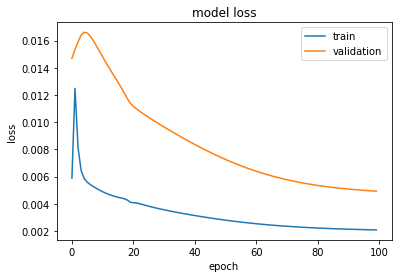

In [67]:
history = model.fit(X_train, y_train, epochs=100, batch_size=1, verbose=2, shuffle=False, validation_split=0.1)
model.summary()
print(history.history.keys())
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

**EVALUACIÓN DEL MODELO**

In [72]:
model.reset_states()
trainPredict = model.predict(X_train, batch_size=1)
# invert predictions
trainPredict = scaler.inverse_transform(trainPredict)
y_pred_train = scaler.inverse_transform(y_train[0])

In [74]:
model.reset_states()
testPredict = model.predict(X_test, batch_size=1)
# invert predictions
testPredict = scaler.inverse_transform(testPredict)
y_pred_test = scaler.inverse_transform(y_test[0])

In [76]:
len(trainPredict)

111

In [96]:
len(trainPredict)

111

In [86]:
X_data[0].shape

(5, 1)

In [120]:
trainPredictPlot = np.zeros(200)
trainPredictPlot[:] = np.nan
trainPredictPlot[5:len(trainPredict)+5] = trainPredict.flatten()
trainPredictPlot

array([           nan,            nan,            nan,            nan,
                  nan, 137131.390625 , 144372.015625 , 154484.953125 ,
       155260.265625 , 145798.15625  , 131489.3125   , 118511.390625 ,
       128075.25     , 126891.1953125, 135650.109375 , 148078.765625 ,
       144748.       , 136784.390625 , 154286.34375  , 171938.140625 ,
       173083.703125 , 163219.125    , 141870.125    , 125156.2734375,
       145262.265625 , 150371.359375 , 155328.28125  , 178494.484375 ,
       166880.3125   , 174077.859375 , 178780.328125 , 196881.03125  ,
       196527.484375 , 183087.203125 , 163427.21875  , 149373.28125  ,
       167842.125    , 171638.765625 , 180042.96875  , 191605.34375  ,
       180221.421875 , 182669.796875 , 215039.       , 224396.25     ,
       235999.5      , 202393.578125 , 189093.765625 , 171489.8125   ,
       196459.796875 , 195048.78125  , 195344.875    , 236274.546875 ,
       229666.203125 , 225292.53125  , 241749.515625 , 262836.8125   ,
      

In [121]:
testPredictPlot = np.zeros(200)
testPredictPlot[:] = np.nan
testPredictPlot[len(trainPredict)+5:X_data.shape[0]+5] = testPredict.flatten()
testPredictPlot

array([         nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,          nan,
                nan,          nan,          nan,       

In [133]:
model.reset_states()
forecastPredict = model.predict(X_train[-1,:,:][np.newaxis,:,:], batch_size=1)

# for i in range(100):

# # invert predictions
# testPredict = scaler.inverse_transform(testPredict)
# y_pred_test = scaler.inverse_transform(y_test[0])

# testPredictPlot = np.zeros(X_data.shape[0]+5)
# testPredictPlot[:] = np.nan
# testPredictPlot[len(trainPredict)+5:X_data.shape[0]+5] = testPredict.flatten()

forecastPredict

array([[0.6677533]], dtype=float32)

In [132]:
X_train[-1,:,:].shape

AttributeError: ignored

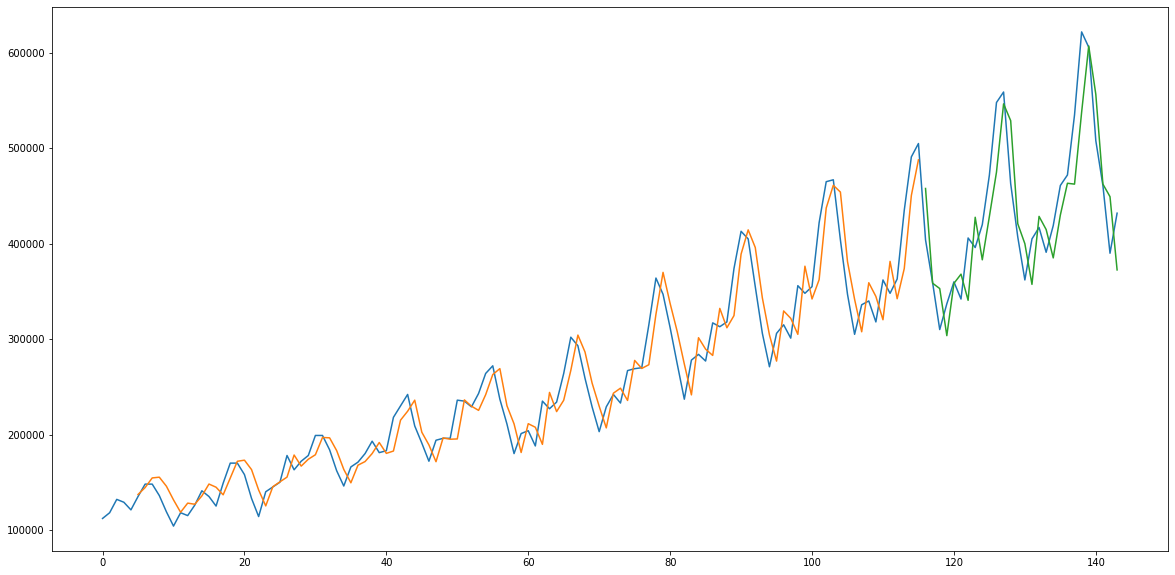

In [122]:
plt.figure(figsize=(20,10))
plt.plot(scaler.inverse_transform(dataset_scaled))
plt.plot(trainPredictPlot)
plt.plot(testPredictPlot)
plt.show()

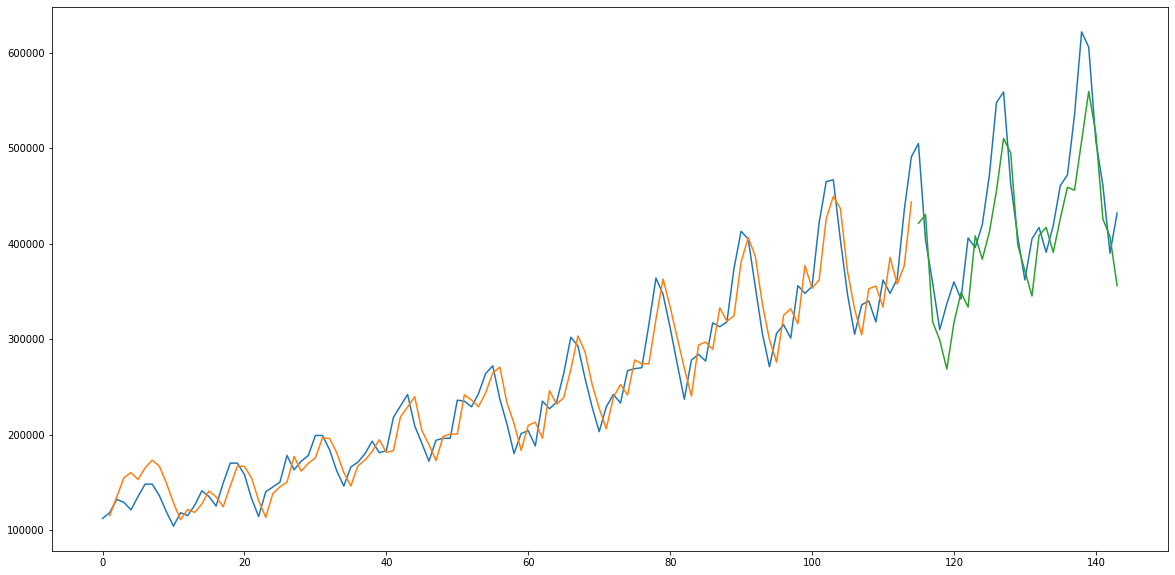

In [ ]:
trainPredictPlot = np.empty_like(dataset_scaled)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[1:len(trainPredict)+1, :] = trainPredict
# shift test predictions for plotting
testPredictPlot = np.empty_like(dataset_scaled)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(trainPredict)+1:len(dataset_scaled)+1, :] = testPredict
# plot baseline and predictions
plt.figure(figsize=(20,10))
plt.plot(scaler.inverse_transform(dataset_scaled))
plt.plot(trainPredictPlot)
plt.plot(testPredictPlot)
plt.show()

**Referencias**

*   https://www.tensorflow.org/tutorials/images/cnn 
*   https://keras.io/api/layers/activation_layers/leaky_relu/ 
*   https://keras.io/api/layers/normalization_layers/batch_normalization/